## 11 Newly Visited Location Patterns (Flag 11)

### Dataset Overview
A constructed WorldTrace case with 250 trajectories. Route geometries come from observed NYC WorldTrace records and retain map-matched coordinates and OSM way identifiers. User, visit sequence, time, mode, vehicle, and weather context are arranged to realize the stated analysis goal.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze patterns of exploration and return visits across the supplied user histories.

Role: Urban mobility analyst


Category: Exploration and preferential return

### Your Objective
Use the provided tables and visual results to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; the supporting timestamped trajectory-point table is loaded into `user_df`.

In [ ]:
dataset_path = 'trajectories.csv'
df = pd.read_csv(dataset_path)
df['departure_time'] = pd.to_datetime(df['departure_time'])
df['arrival_time'] = pd.to_datetime(df['arrival_time'])

In [ ]:
user_dataset_path = 'trajectory_points.csv'
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Across the five users, what share of trajectories revisit familiar locations rather than expand the visited-location set?

#### Analysis action

Compare new-location and return-visit counts for the complete histories.

is_new_location_visit
return visit          222
new-location visit     28
Name: count, dtype: int64
new share 0.112


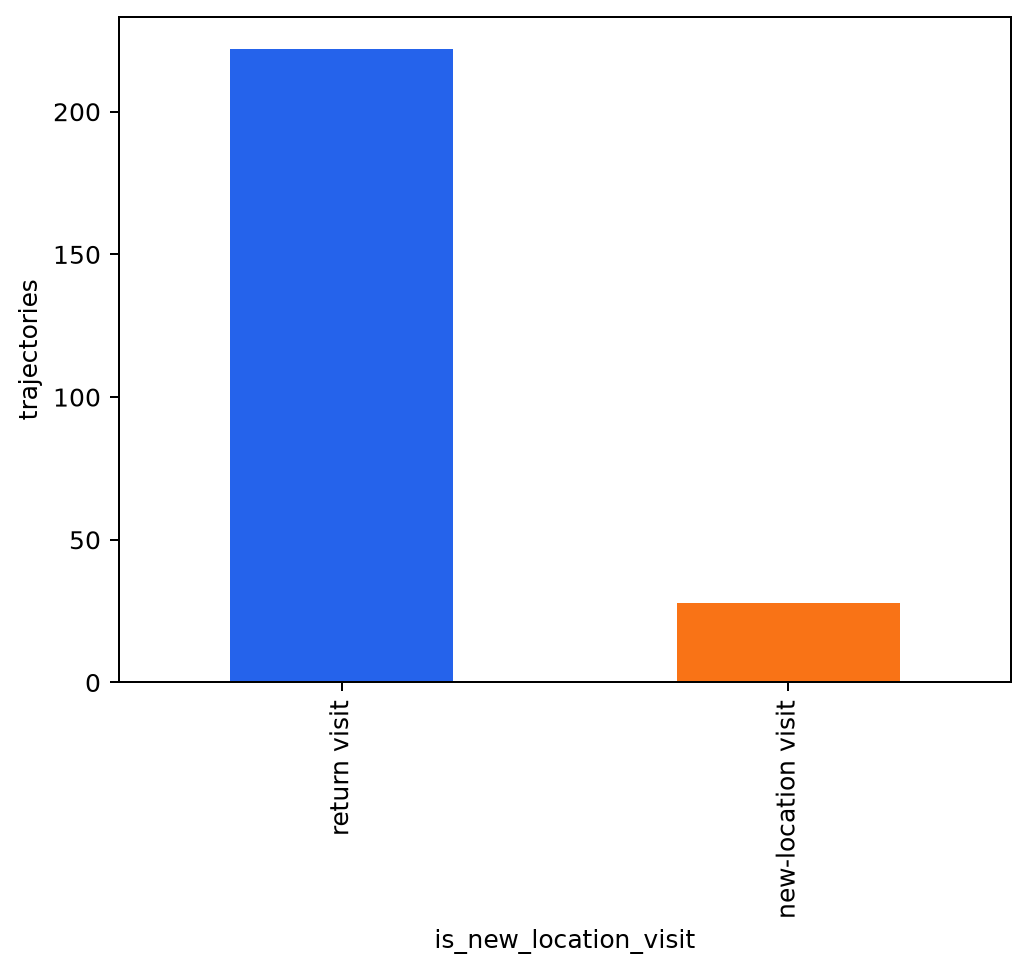

In [1]:
counts=df['is_new_location_visit'].value_counts().rename(index={False:'return visit',True:'new-location visit'}); print(counts); print('new share',df.is_new_location_visit.mean()); counts.plot.bar(color=['#2563eb','#f97316']); plt.ylabel('trajectories'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex11_insight_1",
  "insight": "Most observed visits return to previously visited areas, while only a smaller share expands the user's visited-location set.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_1.png"
    ],
    "title": "Newly Visited Location Patterns: Insight 1",
    "description": "The geographic panel uses map-matched WorldTrace route geometry; the question-specific statistical plot summarizes the corresponding pattern."
  },
  "question": "Across the five users, what share of trajectories revisit familiar locations rather than expand the visited-location set?",
  "actionable_insight": "Compare new-location and return-visit counts for the complete histories.",
  "code": "counts=df['is_new_location_visit'].value_counts().rename(index={False:'return visit',True:'new-location visit'}); print(counts); print('new share',df.is_new_location_visit.mean()); counts.plot.bar(color=['#2563eb','#f97316']); plt.ylabel('trajectories'); plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "matched_road_position"
  ]
}

### **Question 2**: How does the probability of exploration change as each user accumulates more previously visited locations?

#### Analysis action

Group visits by the number of previously known locations and compare new-location shares.

                               mean  count
previous_unique_locations                 
0                          1.000000      5
1                          0.500000     10
2                          0.250000     20
3                          0.125000     40
4                          0.053333     75
5                          0.049180     61
6                          0.026316     38
7                          0.000000      1


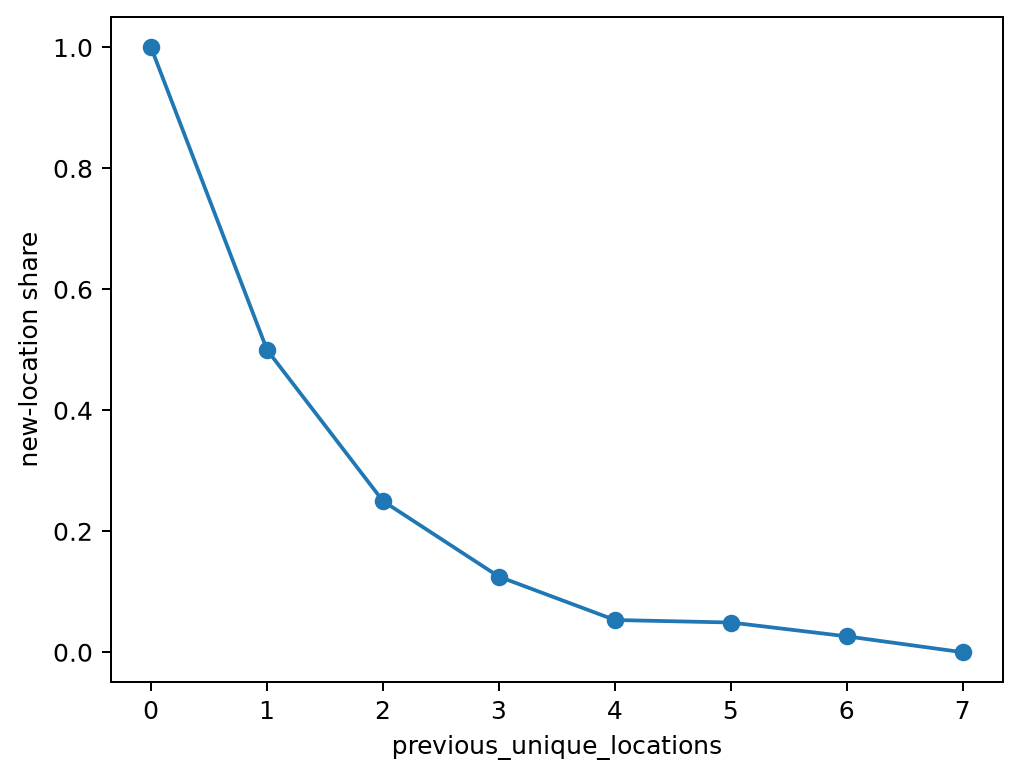

In [2]:
rate=df.groupby('previous_unique_locations').is_new_location_visit.agg(['mean','count']); print(rate); rate['mean'].plot(marker='o'); plt.ylabel('new-location share'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex11_insight_2",
  "insight": "Exploration becomes progressively less frequent as the number of previously visited locations increases.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_2.png"
    ],
    "title": "Newly Visited Location Patterns: Insight 2",
    "description": "The geographic panel uses map-matched WorldTrace route geometry; the question-specific statistical plot summarizes the corresponding pattern."
  },
  "question": "How does the probability of exploration change as each user accumulates more previously visited locations?",
  "actionable_insight": "Group visits by the number of previously known locations and compare new-location shares.",
  "code": "rate=df.groupby('previous_unique_locations').is_new_location_visit.agg(['mean','count']); print(rate); rate['mean'].plot(marker='o'); plt.ylabel('new-location share'); plt.show()",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "matched_road_position"
  ]
}

### **Question 3**: Are return visits distributed evenly across familiar locations, or concentrated on repeatedly visited places?

#### Analysis action

Compare per-user visit counts and within-user shares across locations.

        user_id visited_location  visits  share
0   explorer_01          place_1      20   0.40
1   explorer_01          place_2      14   0.28
2   explorer_01          place_3       8   0.16
3   explorer_01          place_4       8   0.16
4   explorer_02          place_1      16   0.32
5   explorer_02          place_2      16   0.32
6   explorer_02          place_3       8   0.16
7   explorer_02          place_4       6   0.12
8   explorer_02          place_5       4   0.08
9   explorer_03          place_1      24   0.48
10  explorer_03          place_2      12   0.24
13  explorer_03          place_5       6   0.12
11  explorer_03          place_3       4   0.08
12  explorer_03          place_4       2   0.04
14  explorer_03          place_6       2   0.04
15  explorer_04          place_1      20   0.40
16  explorer_04          place_2      10   0.20
17  explorer_04          place_3       8   0.16
18  explorer_04          place_4       6   0.12
19  explorer_04          place_5       2

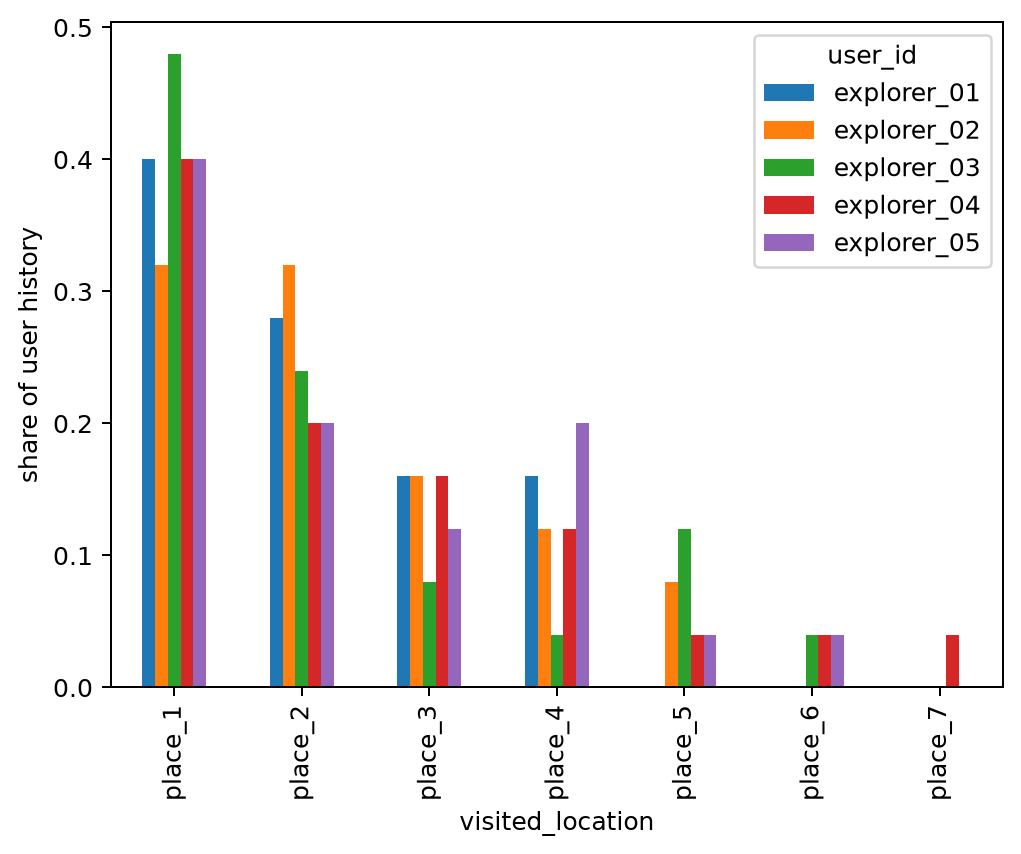

In [3]:
v=df.groupby(['user_id','visited_location']).size().rename('visits').reset_index(); v['share']=v.visits/v.groupby('user_id').visits.transform('sum'); print(v.sort_values(['user_id','visits'],ascending=[True,False])); v.pivot(index='visited_location',columns='user_id',values='share').fillna(0).plot.bar(); plt.ylabel('share of user history'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex11_insight_3",
  "insight": "Return visits are concentrated disproportionately on locations that have already been visited frequently.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_3.png"
    ],
    "title": "Newly Visited Location Patterns: Insight 3",
    "description": "The geographic panel uses map-matched WorldTrace route geometry; the question-specific statistical plot summarizes the corresponding pattern."
  },
  "question": "Are return visits distributed evenly across familiar locations, or concentrated on repeatedly visited places?",
  "actionable_insight": "Compare per-user visit counts and within-user shares across locations.",
  "code": "v=df.groupby(['user_id','visited_location']).size().rename('visits').reset_index(); v['share']=v.visits/v.groupby('user_id').visits.transform('sum'); print(v.sort_values(['user_id','visits'],ascending=[True,False])); v.pivot(index='visited_location',columns='user_id',values='share').fillna(0).plot.bar(); plt.ylabel('share of user history'); plt.show()",
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "matched_road_position"
  ]
}

### Summary of Findings (Flag 11)

Most observed visits return to previously visited areas, while only a smaller share expands the user's visited-location set. Exploration becomes progressively less frequent as the number of previously visited locations increases. Return visits are concentrated disproportionately on locations that have already been visited frequently.